**Lab #2: Probability, Distributions, and Statistical Questions**

In lecture and homework we explored how the convolution can be used to calculate the probability of a sum or average. For this problem we are going to imagine that we are looking for gamma-ray sources (e.g. with the Fermi telescope). In this kind of telescope there is a background of cosmic-rays (electrons and protons, mostly) that provides a discrete noise term across the sky that precisely follows a Poisson distribution. To detect a gamma-ray source, you need to ask what is the probability that the cosmic-ray background would have given you a measurement as signal-like or more than the signal that you received.

To set up the problem, assume in 1 day the average cosmic-ray background is some number X (pick someting btwn 0.5 and 10, with different values for you and your lab partner); and the average number of gamma-rays emitted by your hypothetical source is Y (pick something larger than X).

In [2]:
import numpy as np
import scipy.stats as stats 
import matplotlib.pyplot as plt

# Parameters for ave. cosmic-ray background X and ave. number of gamma-rays emitted Y
# Y is larger than X

X = 4.0 # Average background counts per day
Y = 7.0 # Average source counts per day

print(f"Background rate X = {X} counts per day")
print(f"Source rate Y = {Y} counts per day")

Background rate X = 4.0 counts per day
Source rate Y = 7.0 counts per day


**A) Show how the probability distribution of the background changes as you integrate (sum) for more days.**

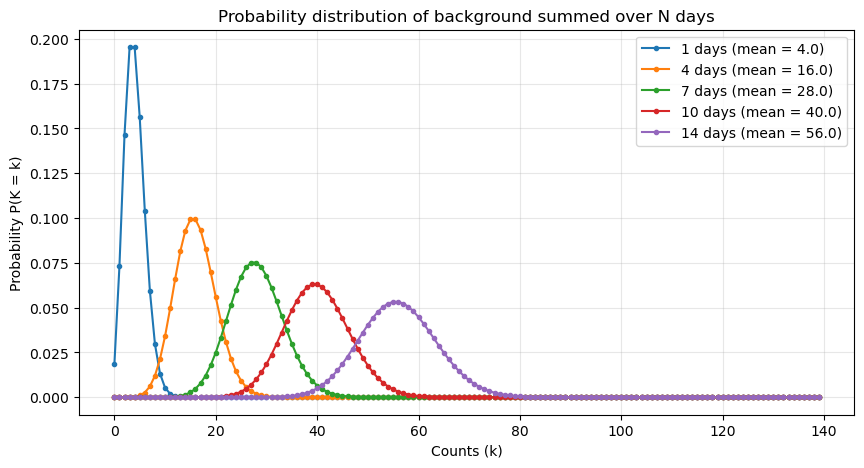

In [3]:
days = [1, 4, 7, 10, 14] # Array of days I'm using 
# Calculating max integer limit. 
k_max = int(max(days) * X * 2.5) # Multiplying largest valye in days array by X and 2.5 then rounding down. 
k_values = np.arange(0, k_max) # Sequence of integers from 0 up to k_max, stored in k_values. 

# Plot size
plt.figure(figsize = (10, 5))

# Looping through list of days and calculating expected rate for Poisson distribution over each span. 
# Probability mass function (pmf) is computed and plotted using matplotlib.
for N in days:
    lambda_N = N * X
    pmf = stats.poisson.pmf(k_values, lambda_N)
    plt.plot(k_values, pmf, marker = 'o', markersize = 3, linestyle = '-', label = f'{N} days (mean = {lambda_N})')

# Plotting details
plt.title("Probability distribution of background summed over N days")
plt.xlabel("Counts (k)")
plt.ylabel("Probability P(K = k)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

As we integrate for more days, the probability distribution of the background begins to shift towards the right (greater mean) and its spread broadens. This is because more summing accumulates more counts and so the expected rates scale linearly which means for $\lambda_N = N \times X$, the probability distribution is shifted and broadened. 

**B) Show that after 5 days, the summed probability distribution is still a Poisson distribution. Explain why this makes sense from a mathematical and conceptual point of view.**

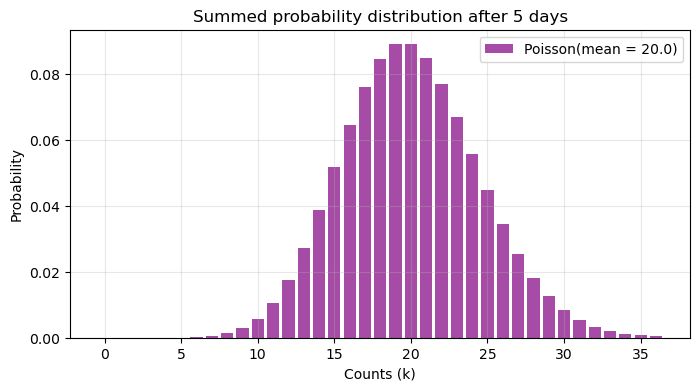

For N = 5 days, expected background = 20.0, variance = 20.0


In [4]:
N_b = 5 # Base count of 5 representing 5 days
lambda_5 = N_b * X # Calculating expected rate paramter for Poisson distribution
# Finding upper limit of k by getting mean and adding 4 times the standard deviation, Result is rounded down to whole number
k_max_b = int(lambda_5 + 4 * np.sqrt(lambda_5)) 
k_values_b = np.arange(0, k_max_b) # creating array of integers starting from 0 going up to K_values, stored. 

pmf_5 = stats.poisson.pmf(k_values_b, lambda_5) # probability mass function calculated

# Plotting 
plt.figure(figsize=(8, 4))
plt.bar(k_values_b, pmf_5, alpha=0.7, color='purple', label=f'Poisson(mean = {lambda_5})')
plt.title("Summed probability distribution after 5 days")
plt.xlabel("Counts (k)")
plt.ylabel("Probability")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print(f"For N = 5 days, expected background = {lambda_5}, variance = {lambda_5}")

After 5 days, the summed probability distribution is still a Poisson distribution. 

Mathematically this makes sense because if we have two Poisson random variables $A$ and $B$ with corresponding rates of $\lambda_1$ and $\lambda_2$, their sum will also be a Poisson random variable of $A + B$ with a rate of $\lambda_1 + \lambda_2$. So summing $N$ daily background measurements where each is distributed as $\text{Poisson}(X)$ will result in $\text{Poisson}(N \times X)$, remaining a Poisson distribution. 

Conceptually, Poisson processes are describing discrete events that occur independently at a constant average rate. So if we take data over multiple days, this doesn't impact the independent events and just increases the window of observation. So the total count continues to follow a Poisson distribution. 

**C) Show how the probability distribution evolves as you average days. Calculate for many different ranges of days, and explore the shape of the distribution as the number of days becomes larger. Discuss this in relation to both B) and the central limit theoem.**